# PDSPL / Phil lens split (v2)

This notebook redoes the LSST Y10 lens split between the PDSPL sample (Paras) and Phil's sample. It uses the **current dissimilarity metric**, read from `../data/samples/pdspl_samples_with_pairs.pkl`, which notebook 03 produced on 2026-06-21. That run used the log-metric pairing, and its results are archived on Zenodo, doi:10.5281/zenodo.24539834.

**Split rule (pair-first, no overlap):** for a dissimilarity cut $c$,
- PDSPL (Paras) gets every lens that appears in at least one pair with $\mathcal{D}_{\rm deflector} \le c$. All of those pairs are used.
- Phil gets every other lens, i.e. lenses whose pairs all have $\mathcal{D}_{\rm deflector} > c$.

This means no lens is in both samples, and every lens is assigned to exactly one of them.

*Old rule (v1, March 2026):* Phil got every lens appearing in **any** pair with $\mathcal{D} > c$, while the PDSPL forecast used every pair with $\mathcal{D} \le c$. A lens can be in both kinds of pair, so the two samples overlapped. With the current metric and $c = 0.033$, 36% of the PDSPL pairs contained a lens that was also in Phil's sample.

The balanced cut is the one that gives both samples the same number of lenses. We save it together with one tighter and one looser cut.

In [1]:
import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

SAMPLE_KEY = "lsst_y10"
CUT_OFFSET = 0.005          # neighbouring cuts = balanced -/+ this
LENS_IDS_PATH = f"lens_ids_dict_{SAMPLE_KEY}_v2.pkl"
SPLIT_CONFIG_PATH = "split_config_v2.json"

In [2]:
with open("../data/samples/pdspl_samples_with_pairs.pkl", "rb") as f:
    pdspl_samples = pickle.load(f)

table = pdspl_samples[SAMPLE_KEY]["table"]
pairs = pdspl_samples[SAMPLE_KEY]["pairs_analysis"]["pairs_table_with_errors"]

n_lenses = len(table)
dissim = np.asarray(pairs["dissimilarity"])
idx1 = np.asarray(pairs["index_1"])
idx2 = np.asarray(pairs["index_2"])

assert len(np.unique(table["lens_id"])) == n_lenses, "lens_id must be unique"
print(f"{n_lenses} lenses, {len(pairs)} pairs")
print(f"pairs per lens: {np.bincount(np.concatenate([idx1, idx2]), minlength=n_lenses).mean():.2f} (mean)")

116471 lenses, 85837 pairs
pairs per lens: 1.47 (mean)


In [3]:
def split_at(cut):
    # Pair-first split. Returns (pair_mask, pdspl_lens_idx, phil_lens_idx).
    pair_mask = dissim <= cut
    pdspl_idx = np.unique(np.concatenate([idx1[pair_mask], idx2[pair_mask]]))
    phil_idx = np.setdiff1d(np.arange(n_lenses), pdspl_idx)
    return pair_mask, pdspl_idx, phil_idx


# Balanced cut: equal number of lenses in both samples
balanced = brentq(lambda c: len(split_at(c)[1]) - len(split_at(c)[2]), 0.0, 0.2, xtol=1e-6)
balanced = round(balanced, 3)
cuts = [round(balanced - CUT_OFFSET, 3), balanced, round(balanced + CUT_OFFSET, 3)]
print("balanced cut:", balanced, "| cuts saved:", cuts)

balanced cut: 0.031 | cuts saved: [0.026, 0.031, 0.036]


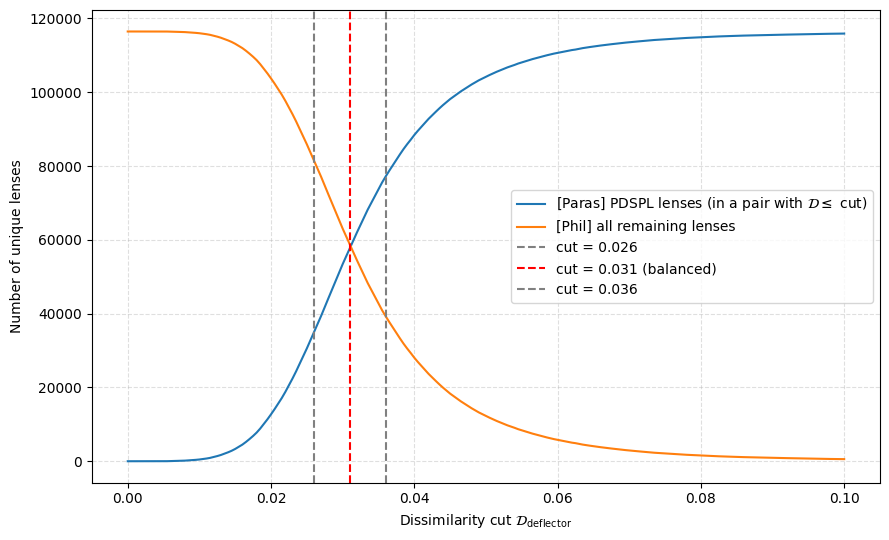

In [4]:
scan = np.linspace(0.0, 0.1, 201)
n_pdspl = np.array([len(split_at(c)[1]) for c in scan])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(scan, n_pdspl, label=r"[Paras] PDSPL lenses (in a pair with $\mathcal{D} \leq$ cut)")
ax.plot(scan, n_lenses - n_pdspl, label="[Phil] all remaining lenses")
for c in cuts:
    ax.axvline(c, color="red" if c == balanced else "grey", ls="--",
               label=f"cut = {c:.3f}" + (" (balanced)" if c == balanced else ""))
ax.set_xlabel(r"Dissimilarity cut $\mathcal{D}_{\rm deflector}$")
ax.set_ylabel("Number of unique lenses")
ax.grid(alpha=0.4, ls="--")
ax.legend()
fig.tight_layout()
fig.savefig("figures/lens_split_vs_dissimilarity_cut_v2.png", dpi=150)
plt.show()

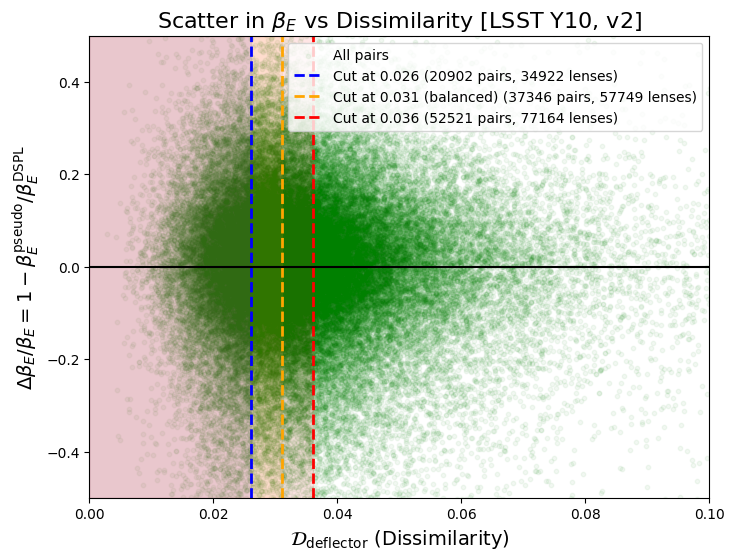

In [5]:
# Scatter in beta_E vs dissimilarity, with the three cuts (v2 version of the March plot)
pairs_beta = pdspl_samples[SAMPLE_KEY]["pairs_analysis"]["pairs_table"]
frac_scatter = 1 - np.asarray(pairs_beta["beta_E_pseudo"]) / np.asarray(pairs_beta["beta_E_DSPL"])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(dissim, frac_scatter, alpha=0.05, s=10, color="green", label="All pairs")
for c, col in zip(cuts, ["blue", "orange", "red"]):
    pair_mask, pdspl_idx, _ = split_at(c)
    ax.axvline(c, color=col, ls="--", lw=2,
               label=f"Cut at {c:.3f}{' (balanced)' if c == balanced else ''} "
                     f"({pair_mask.sum()} pairs, {pdspl_idx.size} lenses)")
    ax.axvspan(0, c, color=col, alpha=0.1)
ax.axhline(0, color="black")
ax.set_xlabel(r"$\mathcal{D}_{\rm deflector}$ (Dissimilarity)", fontsize=14)
ax.set_ylabel(r"$\Delta\beta_E/\beta_E = 1 - \beta_E^{\rm pseudo} / \beta_E^{\rm DSPL}$", fontsize=14)
ax.set_title(r"Scatter in $\beta_E$ vs Dissimilarity [LSST Y10, v2]", fontsize=16)
ax.set_xlim(0, 0.1)
ax.set_ylim(-0.5, 0.5)
ax.legend()
fig.savefig("figures/scatter_in_beta_E_vs_dissimilarity_v2.png", dpi=150)
plt.show()

In [6]:
lens_ids_dict = {}
summary = {"sample": SAMPLE_KEY, "rule": "pair-first", "balanced_cut": balanced,
           "n_lenses_total": n_lenses, "n_pairs_total": int(len(pairs)), "cuts": {}}

for cut in cuts:
    pair_mask, pdspl_idx, phil_idx = split_at(cut)

    # Sanity checks: disjoint and complete
    assert np.intersect1d(pdspl_idx, phil_idx).size == 0
    assert pdspl_idx.size + phil_idx.size == n_lenses
    assert np.all(np.isin(idx1[pair_mask], pdspl_idx)) and np.all(np.isin(idx2[pair_mask], pdspl_idx))

    tag = f"{cut:.3f}"
    lens_ids_dict[f"dissimilarity_cut_leq_{tag}"] = np.asarray(table["lens_id"][pdspl_idx])  # Paras / PDSPL
    lens_ids_dict[f"dissimilarity_cut_gt_{tag}"] = np.asarray(table["lens_id"][phil_idx])    # Phil
    lens_ids_dict[f"pdspl_pair_rows_leq_{tag}"] = np.flatnonzero(pair_mask)                    # rows of pairs table

    summary["cuts"][tag] = {"n_pdspl_lenses": int(pdspl_idx.size), "n_phil_lenses": int(phil_idx.size),
                            "n_pdspl_pairs": int(pair_mask.sum())}
    print(f"cut {tag}: PDSPL {pdspl_idx.size} lenses / {pair_mask.sum()} pairs | Phil {phil_idx.size} lenses")

with open(LENS_IDS_PATH, "wb") as f:
    pickle.dump(lens_ids_dict, f)
with open(SPLIT_CONFIG_PATH, "w") as f:
    json.dump(summary, f, indent=2)
print("saved", LENS_IDS_PATH, "and", SPLIT_CONFIG_PATH)

cut 0.026: PDSPL 34922 lenses / 20902 pairs | Phil 81549 lenses
cut 0.031: PDSPL 57749 lenses / 37346 pairs | Phil 58722 lenses
cut 0.036: PDSPL 77164 lenses / 52521 pairs | Phil 39307 lenses
saved lens_ids_dict_lsst_y10_v2.pkl and split_config_v2.json


## How Phil selects his lenses

`lens_ids_dict_lsst_y10_v2.pkl` maps these keys to arrays:
- `dissimilarity_cut_gt_<cut>`: the `lens_id`s in **Phil's** sample.
- `dissimilarity_cut_leq_<cut>`: the `lens_id`s in the **PDSPL** sample.
- `pdspl_pair_rows_leq_<cut>`: the PDSPL pairs, as row indices into `pairs_table`.

For each cut, the first two lists are disjoint and together contain every lens.

In [7]:
from astropy.table import Table

with open(LENS_IDS_PATH, "rb") as f:
    loaded = pickle.load(f)

ggl = Table.read("../data/GGL_Catalogs/GGL_20000.0_SQDEG_LSSTY10_SNR_20_seeing_0.5_contrast_02.fits")
key = f"dissimilarity_cut_gt_{balanced:.3f}"
phil_table = ggl[np.isin(ggl["lens_id"], loaded[key])]
print(f"Phil's sample at balanced cut {balanced:.3f}: {len(phil_table)} lenses (expected {len(loaded[key])})")

Phil's sample at balanced cut 0.031: 58722 lenses (expected 58722)
